# Intermittent Demand Forecasting
## Croston's Method

Croston's method is designed for intermittent demand: a time series with many zero-demand periods and occasional non-zero demand.

It separately smooths:

- **Non-zero demand size** (`z`): the size of each demand occurrence.
- **Inter-demand interval** (`p`): the number of periods between non-zero demand occurrences.

The forecast per period is:

$$\hat{y}_{t+h} = \frac{\hat{z}_t}{\hat{p}_t}, \qquad h=1,2,\ldots$$

The forecast is constant across future horizons unless the estimates are updated with new observations.

This notebook implements the method transparently with Python, NumPy, and pandas. It uses synthetic data; replace it with your own demand series when experimenting.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True
np.random.seed(42)

## 1. Generate an example intermittent-demand series

We simulate 120 monthly periods. Most months have zero demand; when demand occurs, its size varies. This creates the sparse pattern these methods are designed for.

In [2]:
n_periods = 120
occurs = np.random.rand(n_periods) < 0.25
demand_sizes = np.random.randint(5, 31, size=n_periods)
demand = np.where(occurs, demand_sizes, 0)

dates = pd.date_range("2016-01-01", periods=n_periods, freq="MS")
series = pd.Series(demand, index=dates, name="Demand")

print(series.head(24))
print(f"Zero-demand periods: {(series == 0).sum()} / {len(series)}")
print(f"Non-zero demand periods: {(series > 0).sum()} / {len(series)}")

2016-01-01     0
2016-02-01     0
2016-03-01     0
2016-04-01     0
2016-05-01     5
2016-06-01     5
2016-07-01    29
2016-08-01     0
2016-09-01     0
2016-10-01     0
2016-11-01    13
2016-12-01     0
2017-01-01     0
2017-02-01    10
2017-03-01    12
2017-04-01    13
2017-05-01     0
2017-06-01     0
2017-07-01     0
2017-08-01     0
2017-09-01     0
2017-10-01    28
2017-11-01     0
2017-12-01     0
Freq: MS, Name: Demand, dtype: int64
Zero-demand periods: 85 / 120
Non-zero demand periods: 35 / 120


## 2. Visualize demand

A time plot helps identify the defining feature: many periods with no demand, separated by irregular demand occurrences.

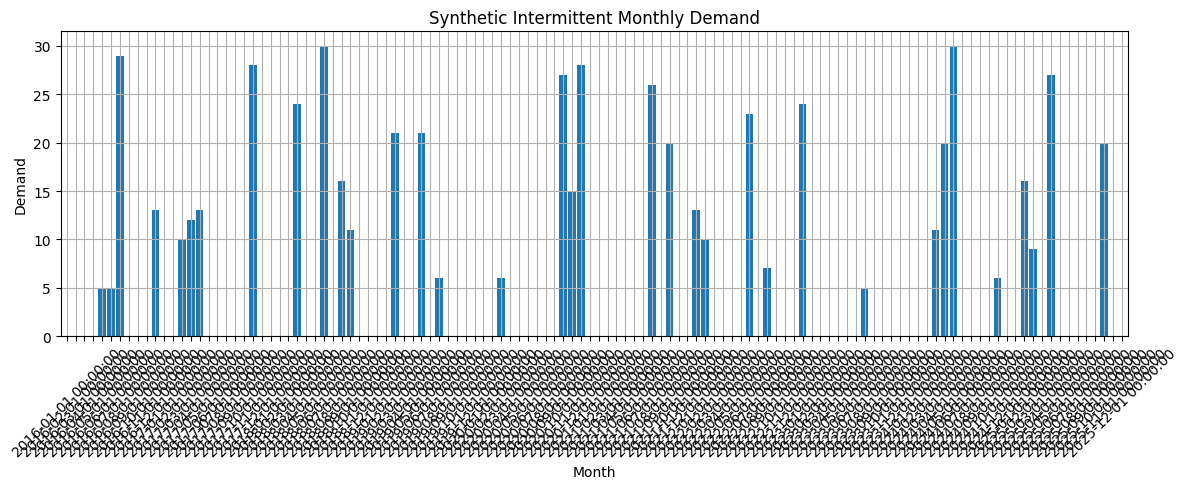

In [3]:
ax = series.plot(kind="bar", width=0.85)
ax.set_title("Synthetic Intermittent Monthly Demand")
ax.set_xlabel("Month")
ax.set_ylabel("Demand")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 3. Croston algorithm

For each non-zero observation, update the estimated demand size and the estimated interval. Zero-demand periods do not update the size estimate; they increase the interval counter.

This notebook initializes at the first non-zero demand. The first interval estimate is the number of periods from the beginning of the series through that first occurrence. Later intervals count periods since the previous non-zero occurrence. This is one explicit initialization convention; implementations can differ.

In [4]:
def croston_forecast(y, alpha=0.1):
    """Return one-step fitted values, final forecast, and state history.

    Initialization: first non-zero demand size and elapsed period count
    through its occurrence. Thereafter, update size and interval only
    when demand is non-zero.
    """
    y = np.asarray(y, dtype=float)
    if y.ndim != 1:
        raise ValueError("y must be one-dimensional")
    if len(y) == 0:
        raise ValueError("y must not be empty")
    if np.any(y < 0):
        raise ValueError("Croston's method expects non-negative demand")
    if not 0 < alpha <= 1:
        raise ValueError("alpha must be in (0, 1]")

    nonzero_idx = np.flatnonzero(y > 0)
    fitted = np.zeros(len(y), dtype=float)

    if len(nonzero_idx) == 0:
        return {
            "fitted": fitted,
            "forecast": 0.0,
            "history": pd.DataFrame(columns=["period", "demand_size_est", "interval_est", "forecast"])
        }

    first = nonzero_idx[0]
    z_hat = y[first]
    p_hat = first + 1  # elapsed periods from start through first occurrence
    q = 0
    history = []

    # Before first non-zero observation, no demand rate has been established.
    for t, value in enumerate(y):
        if t < first:
            history.append((t, np.nan, np.nan, 0.0))
            continue

        if t == first:
            fitted[t] = z_hat / p_hat
            history.append((t, z_hat, p_hat, fitted[t]))
            q = 0
            continue

        q += 1
        if value > 0:
            z_hat = z_hat + alpha * (value - z_hat)
            p_hat = p_hat + alpha * (q - p_hat)
            q = 0

        fitted[t] = z_hat / p_hat
        history.append((t, z_hat, p_hat, fitted[t]))

    history_df = pd.DataFrame(
        history, columns=["period", "demand_size_est", "interval_est", "forecast"]
    )
    return {"fitted": fitted, "forecast": float(z_hat / p_hat), "history": history_df}

## 4. Run Croston's method

Choose a smoothing parameter. A larger `alpha` reacts more strongly to newly observed demand sizes and intervals; a smaller value smooths more gradually.

In [5]:
alpha = 0.1
result = croston_forecast(series.values, alpha=alpha)

croston_fitted = pd.Series(result["fitted"], index=series.index)
croston_next = result["forecast"]

print(f"Alpha: {alpha}")
print(f"Croston forecast per month: {croston_next:.3f}")
display(result["history"].tail(10))

Alpha: 0.1
Croston forecast per month: 4.745


,period,demand_size_est,interval_est,forecast
110,110,15.259253,3.405868,4.480282
111,111,16.433327,3.265282,5.032744
112,112,16.433327,3.265282,5.032744
113,113,16.433327,3.265282,5.032744
114,114,16.433327,3.265282,5.032744
115,115,16.433327,3.265282,5.032744
116,116,16.433327,3.265282,5.032744
117,117,16.789995,3.538753,4.744607
118,118,16.789995,3.538753,4.744607
119,119,16.789995,3.538753,4.744607


## 5. Plot actual demand and Croston fitted rate

The fitted Croston value represents an estimated average demand rate per period. It is not intended to reproduce the exact timing of each intermittent demand event.

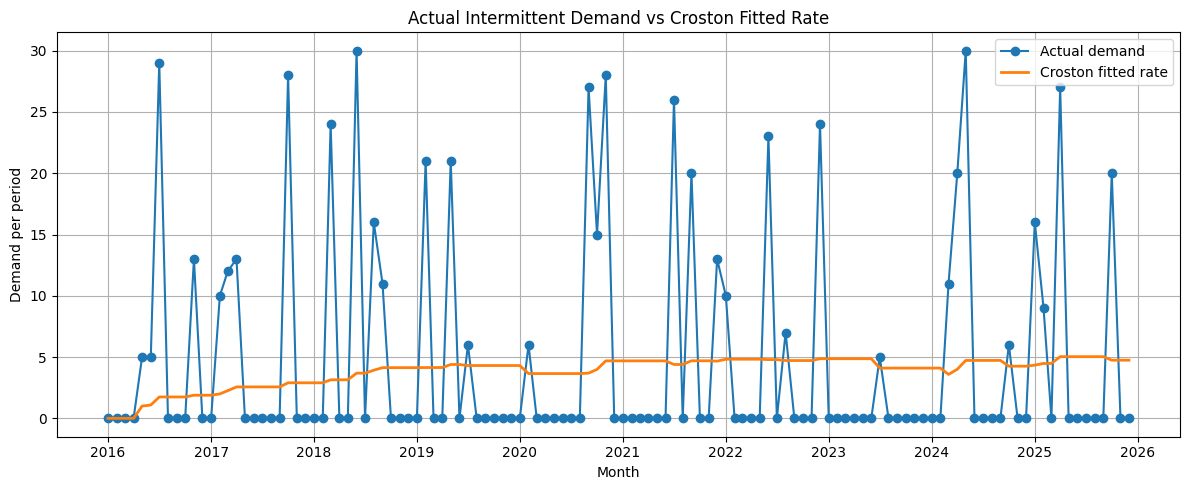

In [6]:
plt.figure()
plt.plot(series.index, series.values, marker="o", label="Actual demand")
plt.plot(series.index, croston_fitted.values, label="Croston fitted rate", linewidth=2)
plt.title("Actual Intermittent Demand vs Croston Fitted Rate")
plt.xlabel("Month")
plt.ylabel("Demand per period")
plt.legend()
plt.tight_layout()
plt.show()

## 6. Forecast future periods

Croston's method produces a constant rate forecast for each future period until new observations arrive and the estimates are updated.

,Croston forecast
2026-01-01,4.744607
2026-02-01,4.744607
2026-03-01,4.744607
2026-04-01,4.744607
2026-05-01,4.744607
2026-06-01,4.744607
2026-07-01,4.744607
2026-08-01,4.744607
2026-09-01,4.744607
2026-10-01,4.744607


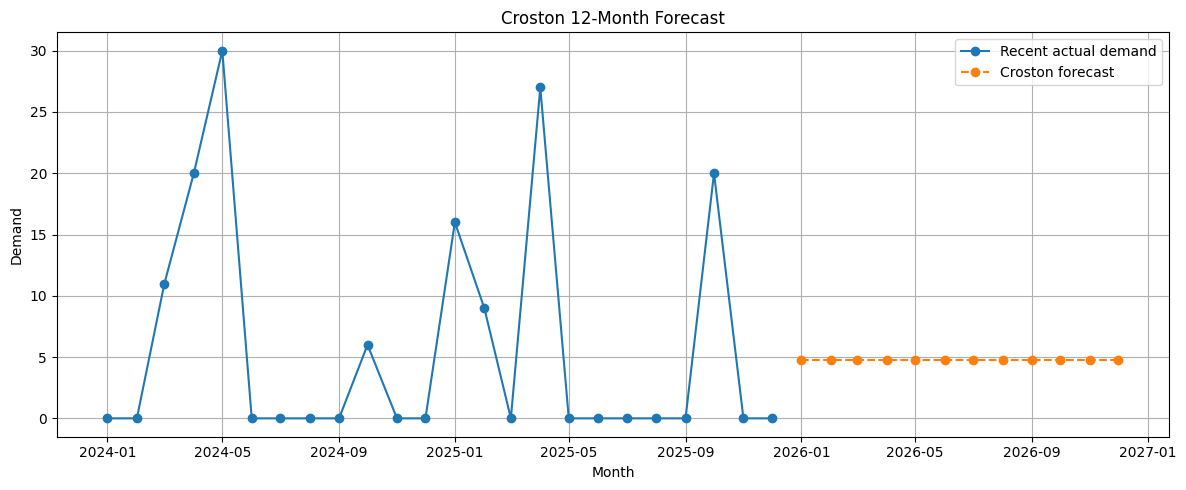

In [7]:
horizon = 12
future_dates = pd.date_range(series.index[-1] + pd.offsets.MonthBegin(1),
                             periods=horizon, freq="MS")
future_forecast = pd.Series(croston_next, index=future_dates, name="Croston forecast")

display(future_forecast.to_frame())
plt.figure()
plt.plot(series.index[-24:], series.values[-24:], marker="o", label="Recent actual demand")
plt.plot(future_forecast.index, future_forecast.values, marker="o",
         linestyle="--", label="Croston forecast")
plt.title("Croston 12-Month Forecast")
plt.xlabel("Month")
plt.ylabel("Demand")
plt.legend()
plt.tight_layout()
plt.show()

## 7. Compare with simple baselines

For intermittent demand, useful simple references include the overall historical average and the Naive forecast. These are not necessarily strong intermittent-demand methods, but they provide context.

In [8]:
mean_forecast = float(series.mean())
naive_forecast = float(series.iloc[-1])

comparison = pd.DataFrame({
    "Method": ["Historical Average", "Naive", "Croston"],
    "Forecast per month": [mean_forecast, naive_forecast, croston_next]
})
display(comparison)

,Method,Forecast per month
0,Historical Average,4.891667
1,Naive,0.000000
2,Croston,4.744607


## 8. Chronological holdout evaluation

Evaluate on a later holdout segment. Since the method is stateful, the forecast is generated using only the training segment and held constant across the test horizon. Metrics such as MAE and RMSE are included. MAPE is often unsuitable for intermittent demand because actual values can be zero; WMAPE is also affected by the total volume and should be interpreted carefully.

Holdout MAE:   7.159
Holdout RMSE:  9.545
Holdout WMAPE: 123.605%


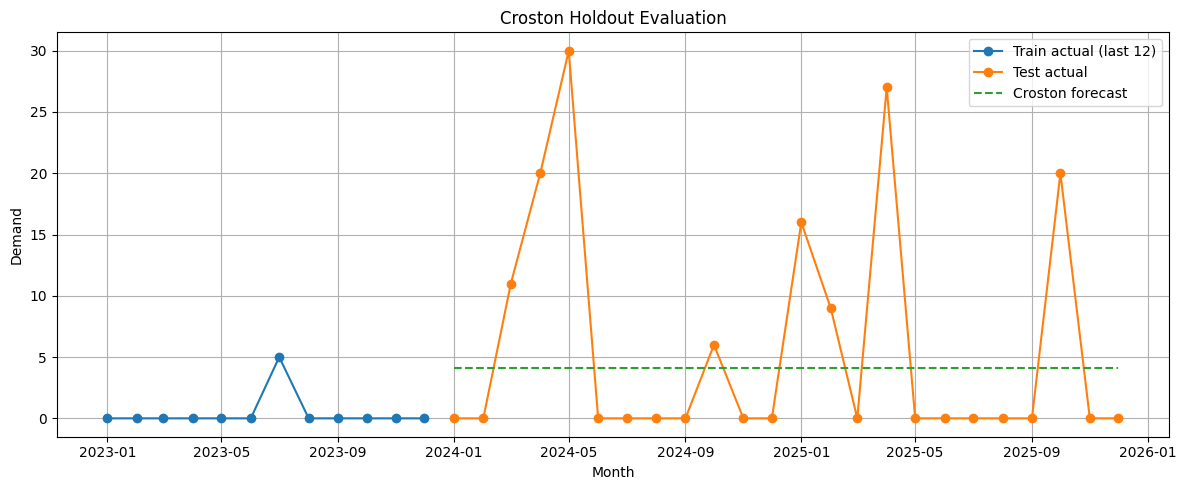

In [9]:
split = int(len(series) * 0.8)
train = series.iloc[:split]
test = series.iloc[split:]

train_result = croston_forecast(train.values, alpha=alpha)
pred = np.full(len(test), train_result["forecast"], dtype=float)
actual = test.values

mae = np.mean(np.abs(actual - pred))
rmse = np.sqrt(np.mean((actual - pred) ** 2))
wmape = np.sum(np.abs(actual - pred)) / np.sum(np.abs(actual)) if np.sum(np.abs(actual)) else np.nan

print(f"Holdout MAE:   {mae:.3f}")
print(f"Holdout RMSE:  {rmse:.3f}")
print(f"Holdout WMAPE: {wmape:.3%}" if not np.isnan(wmape) else "Holdout WMAPE: undefined (zero total actual demand)")

plt.figure()
plt.plot(train.index[-12:], train.values[-12:], marker="o", label="Train actual (last 12)")
plt.plot(test.index, test.values, marker="o", label="Test actual")
plt.plot(test.index, pred, linestyle="--", label="Croston forecast")
plt.title("Croston Holdout Evaluation")
plt.xlabel("Month")
plt.ylabel("Demand")
plt.legend()
plt.tight_layout()
plt.show()

## 9. Experiment with alpha

Compare several smoothing parameters on the same chronological split. For a fair model-selection workflow, choose alpha using a validation period, then report final performance on a separate untouched test period.

In [10]:
alphas = [0.05, 0.1, 0.2, 0.3, 0.5]
rows = []
for a in alphas:
    r = croston_forecast(train.values, alpha=a)
    p = np.full(len(test), r["forecast"])
    rows.append({
        "alpha": a,
        "forecast": r["forecast"],
        "MAE": np.mean(np.abs(test.values - p)),
        "RMSE": np.sqrt(np.mean((test.values - p) ** 2))
    })

alpha_results = pd.DataFrame(rows).sort_values("MAE")
display(alpha_results)

,alpha,forecast,MAE,RMSE
4,0.50,2.246464,6.540488,10.040753
3,0.30,3.130364,6.835121,9.763749
0,0.05,3.496956,6.957319,9.670262
2,0.20,3.700588,7.025196,9.623974
1,0.10,4.101312,7.158771,9.544923


## 10. Advantages, limitations, and practical notes

**Advantages**
- Designed for intermittent and lumpy demand.
- Separates demand occurrence size from occurrence timing.
- Simple, computationally inexpensive, and produces a stable rate forecast.

**Limitations**
- Standard Croston is known to be biased under common assumptions.
- Does not model seasonality, trend, or changing occurrence probability explicitly.
- A constant forecast may not respond quickly to structural changes.
- Results can depend on initialization and smoothing parameter.

**Practical notes**
- Use non-negative demand data at a consistent time granularity.
- Investigate whether zeros mean true no-demand periods or missing data / stockouts.
- Tune alpha on a validation period, not the final test set.
- Consider SBA or TSB as alternatives, and evaluate at the business-relevant aggregation level.